# BT4012 Group 1 · Phishing website detection

## 1. Set up the run

Install the pinned dependencies in the [README](README.md) and launch Jupyter from the repository root.
The original CSV is included at [data/dataset_full.csv](data/dataset_full.csv).

In [2]:
import hashlib
import json
import os
import platform
import time
from importlib.metadata import version
from pathlib import Path

TARGET = "phishing"
SEED = 42
N_PHISH = 3064
CPU_THREADS = min(4, os.cpu_count() or 1)
RUN_FEATURE_RANKING = os.environ.get("BT4012_RUN_FEATURE_RANKING", "0") == "1"
RUN_HYPERPARAMETER_SEARCH = os.environ.get("BT4012_RUN_HYPERPARAMETER_SEARCH", "0") == "1"
DATA_PATH = Path("dataset_full.csv")
OUTPUT_DIR = Path("outputs")
DATA_SHA256 = "87da36a20c8c1a9d13db5899514071907179c0fe790dc2ea4f0811957d68745d"

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = str(CPU_THREADS if variable == "OMP_NUM_THREADS" else 1)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import parallel_backend
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

started = time.monotonic()
OUTPUT_DIR.mkdir(exist_ok=True)
receipt_path = OUTPUT_DIR / "reproduction_receipt.json"
receipt_path.unlink(missing_ok=True)
print(f"Feature ranking: {RUN_FEATURE_RANKING}. Hyperparameter search: {RUN_HYPERPARAMETER_SEARCH}.")

Feature ranking: False. Hyperparameter search: False.


## 2. Load, deduplicate and sample

Keep all distinct legitimate rows and sample 3,064 phishing rows without replacement using seed 42.

In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Missing bundled dataset at {DATA_PATH}. Open the notebook from the repository root."
    )

if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != DATA_SHA256:
    raise ValueError(f"{DATA_PATH} does not match the bundled full dataset. Restore the original CSV from Git.")

raw = pd.read_csv(DATA_PATH)
assert raw.shape == (88647, 112)
distinct = raw.drop_duplicates().reset_index(drop=True)
legitimate = distinct.loc[distinct[TARGET] == 0]
phishing = distinct.loc[distinct[TARGET] == 1].sample(n=N_PHISH, random_state=SEED)
df = pd.concat([legitimate, phishing]).sample(frac=1, random_state=SEED).reset_index(drop=True)
assert tuple(df[TARGET].value_counts().sort_index()) == (56712, 3064)
counts = {
    "Original": raw[TARGET].value_counts().sort_index(),
    "Deduplicated": distinct[TARGET].value_counts().sort_index(),
    "Imbalanced sample": df[TARGET].value_counts().sort_index(),
}
display(pd.DataFrame(counts).T.rename(columns={0: "Legitimate", 1: "Phishing"}))

phishing,Legitimate,Phishing
Original,58000,30647
Deduplicated,56712,30497
Imbalanced sample,56712,3064


## 3. Recreate the 75-feature train and test files

Structural absence becomes zero with a presence flag. Failed lookups receive missingness indicators. The original sparsity rules drop extremely rare counts and convert other sparse counts to presence flags.

In [4]:
const = [c for c in df.columns if c != TARGET and df[c].nunique() == 1]
df = df.drop(columns=const)

# 4b. -1 = 'missing / not applicable' codes
#   (i) structural: URL has no directory / file / query-string -> whole block is -1
blocks = {"directory": [c for c in df if c.endswith("_directory") or c == "directory_length"],
          "file":      [c for c in df if c.endswith("_file") or c == "file_length"],
          "params":    [c for c in df if c.endswith("_params") or c == "params_length"]}
for name, cols in blocks.items():
    df[f"has_{name}"] = (df[cols[0]] != -1).astype(int)
    df[cols] = df[cols].replace(-1, 0)

#   (ii) external look-ups that failed (WHOIS, DNS, response time, Google index ...)
lookup = [c for c in df if c != TARGET and (df[c] == -1).any()]
for c in lookup:
    df[f"{c}_missing"] = (df[c] == -1).astype(int)
    df[c] = df[c].replace(-1, np.nan)

# 4c. sanity checks
binary = [c for c in df if c != TARGET and df[c].dropna().nunique() <= 2]
numeric = [c for c in df if c not in binary + [TARGET]]
neg = [c for c in numeric if (df[c] < 0).any()]

# drop columns that became constant
const2 = [c for c in df if c != TARGET and df[c].nunique(dropna=True) <= 1]
if const2:
    df = df.drop(columns=const2)
    binary = [c for c in binary if c not in const2]
    numeric = [c for c in numeric if c not in const2]

# 4d. sparse count columns: >95% zeros -> skew is structural and no transform can fix it.
#     <0.1% non-zero  -> near-zero variance, drop
#     0.1%-5% non-zero -> convert to 0/1 presence flag
nz = (df[numeric].fillna(0) != 0).mean()
nzv = [c for c in numeric if nz[c] < 0.001]
sparse = [c for c in numeric if 0.001 <= nz[c] < 0.05]
df = df.drop(columns=nzv)
for c in sparse:
    df[c] = (df[c].fillna(0) > 0).astype(int)
numeric = [c for c in numeric if c not in nzv + sparse]
binary = binary + sparse



assert not neg, f"Unexpected negative numeric features: {neg}"
assert (len(numeric), len(binary)) == (22, 53)
print(f"Columns removed: {len(const) + len(const2) + len(nzv)}. Presence conversions: {len(sparse)}.")

Columns removed: 49. Presence conversions: 24.


Fit the continuous transforms on the training split. The group’s downstream notebooks used CSVs rounded to six decimals, so subsequent cells read those same exports.

In [5]:
class Prep:
    def fit(self, X):
        self.med = X[numeric].median()
        self.mode = X[binary].mode().iloc[0]
        Xi = self._impute(X)
        self.skewed = [c for c in numeric if abs(Xi[c].skew()) > 1]
        self.pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(Xi[self.skewed])
        Xl = self._power(Xi)
        self.scaler = StandardScaler().fit(Xl[numeric])
        return self

    def _impute(self, X):
        X = X.copy()
        X[numeric] = X[numeric].fillna(self.med)
        X[binary] = X[binary].fillna(self.mode).astype(int)
        return X

    def _power(self, X):
        X = X.copy()
        X[self.skewed] = self.pt.transform(X[self.skewed])   # Yeo-Johnson skew correction
        return X

    def transform(self, X):
        X = self._power(self._impute(X))
        X[numeric] = self.scaler.transform(X[numeric])
        return X

y = df[TARGET]
X = df.drop(columns=TARGET)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
assert not Xtr.index.intersection(Xte.index).size
preprocessor = Prep().fit(Xtr)
processed = {}
for split, features, labels, expected_counts in (
    ("train", Xtr, ytr, (45369, 2451)),
    ("test", Xte, yte, (11343, 613)),
):
    path = OUTPUT_DIR / f"{split}_processed.csv"
    frame = preprocessor.transform(features).assign(**{TARGET: labels.to_numpy()})
    assert frame.shape[1] == 76
    assert tuple(frame[TARGET].value_counts().sort_index()) == expected_counts
    assert np.isfinite(frame.to_numpy()).all()
    frame.to_csv(path, index=False, float_format="%.6f")
    processed[split] = pd.read_csv(path)
    print(f"{split}: {frame.shape[0]:,} rows, {int(frame[TARGET].sum()):,} phishing")
print(f"Power-transformed features: {len(preprocessor.skewed)}")

train: 47,820 rows, 2,451 phishing
test: 11,956 rows, 613 phishing
Power-transformed features: 21


## 4. Analyse correlated and redundant features

The group removed three exact duplicate predictors identified in the training data. Pearson and
Spearman correlations use the training split at both feature counts. The optional leave-one-feature-out
step measures the change in five-fold average precision when each feature is removed in turn.

In [6]:
CORRELATION_THRESHOLD = 0.90
DROP_TO_KEEP = {
    "qty_space_url": "qty_space_directory",
    "params_length": "has_params",
    "has_file": "has_directory",
}
MODEL_PARAMS = dict(
    max_iter=80, max_leaf_nodes=15, max_bins=63, learning_rate=0.1,
    l2_regularization=1, early_stopping=False, random_state=SEED,
)

for drop, keep in DROP_TO_KEEP.items():
    if not processed["train"][drop].equals(processed["train"][keep]):
        raise ValueError(f"Expected identical training columns: {drop} and {keep}")

reduced = {}
for split, frame in processed.items():
    reduced[split] = frame.drop(columns=list(DROP_TO_KEEP))
    assert reduced[split].shape[1] == 73
    reduced[split].to_csv(OUTPUT_DIR / f"{split}_processed_72_features.csv", index=False)
display(pd.DataFrame(DROP_TO_KEEP.items(), columns=["Removed", "Retained"]))

,Removed,Retained
0,qty_space_url,qty_space_directory
1,params_length,has_params
2,has_file,has_directory


In [7]:
def correlations(X: pd.DataFrame, output_dir: Path, suffix: str):
    """Predictor-predictor relationships; exclude the target before calling."""
    pearson = X.corr(method="pearson")
    spearman = X.corr(method="spearman")
    records = []
    for i, a in enumerate(X.columns):
        for b in X.columns[i + 1:]:
            p, s = float(pearson.loc[a, b]), float(spearman.loc[a, b])
            strength = max(abs(p), abs(s))
            records.append(dict(
                feature_1=a, feature_2=b, pearson=p, spearman=s,
                max_absolute_correlation=strength,
                high_correlation=strength >= CORRELATION_THRESHOLD,
                exact_duplicate=np.array_equal(X[a].to_numpy(), X[b].to_numpy()),
            ))
    pairs = pd.DataFrame(records).sort_values(
        "max_absolute_correlation", ascending=False, kind="stable"
    )
    pairs.to_csv(output_dir / f"correlation_pairs_{suffix}.csv", index=False)
    pairs.loc[pairs.high_correlation].to_csv(
        output_dir / f"high_correlation_pairs_{suffix}.csv", index=False
    )
    pearson.to_csv(output_dir / f"pearson_matrix_{suffix}.csv")
    spearman.to_csv(output_dir / f"spearman_matrix_{suffix}.csv")
    print(f"{suffix}: {len(pairs)} pairs; {pairs.high_correlation.sum()} high pairs", flush=True)
    return pearson, spearman, pairs


def rank_features(X: pd.DataFrame, y: pd.Series, output_dir: Path, suffix: str):
    """Retrain after each feature removal using identical folds and settings."""
    values = X.to_numpy(dtype=np.float64)
    target = y.to_numpy(dtype=int)
    folds = list(StratifiedKFold(
        n_splits=5, shuffle=True, random_state=SEED
    ).split(values, target))
    fold_records = []

    def evaluate(columns, experiment):
        scores = []
        for fold, (train_idx, valid_idx) in enumerate(folds, 1):
            model = HistGradientBoostingClassifier(**MODEL_PARAMS)
            with threadpool_limits(limits=2):
                model.fit(values[train_idx][:, columns], target[train_idx])
                probabilities = model.predict_proba(values[valid_idx][:, columns])[:, 1]
            ap = float(average_precision_score(target[valid_idx], probabilities))
            scores.append(ap)
            fold_records.append(dict(
                experiment=experiment, fold=fold, train_rows=len(train_idx),
                validation_rows=len(valid_idx),
                validation_phishing=int(target[valid_idx].sum()), AP=ap,
            ))
        return np.array(scores)

    n_features = X.shape[1]
    baseline = evaluate(list(range(n_features)), "Baseline")
    rows = []
    start = time.monotonic()
    for i, feature in enumerate(X.columns):
        without = evaluate([j for j in range(n_features) if j != i], feature)
        delta = baseline - without
        rows.append(dict(
            feature=feature, baseline_AP=float(baseline.mean()),
            without_AP=float(without.mean()), delta_AP=float(delta.mean()),
            delta_SD=float(delta.std(ddof=1)), positive_folds=int((delta > 0).sum()),
            min_delta=float(delta.min()), max_delta=float(delta.max()),
            **{f"fold_{k + 1}_AP_loss": float(v) for k, v in enumerate(delta)},
        ))
        if (i + 1) % 10 == 0 or i + 1 == n_features:
            print(f"{suffix} features: {i+1}/{n_features} assessed ({time.monotonic()-start:.0f}s)", flush=True)
    ranking = pd.DataFrame(rows).sort_values("delta_AP", ascending=False, kind="stable")
    ranking.insert(0, "rank", range(1, n_features + 1))
    ranking.to_csv(output_dir / f"feature_ranking_{suffix}.csv", index=False)
    pd.DataFrame(fold_records).to_csv(output_dir / f"ranking_fold_results_{suffix}.csv", index=False)
    return ranking, baseline

In [8]:
def integrated_ranking(ranking, X, pearson, spearman, output_dir):
    """One flat CSV combining the refreshed ranking and retained-feature correlation."""
    rows = []
    for r in ranking.to_dict("records"):
        a = r["feature"]
        peers = sorted(
            [b for b in X if b != a],
            key=lambda b: -max(abs(pearson.loc[a, b]), abs(spearman.loc[a, b])),
        )
        high = [b for b in peers if max(
            abs(pearson.loc[a, b]), abs(spearman.loc[a, b])
        ) >= CORRELATION_THRESHOLD]
        b = peers[0]
        rows.append(dict(
            **r, processed_type="Binary 0/1" if set(X[a].unique()) <= {0, 1} else "Numeric (processed)",
            strongest_peer=b, pearson_with_peer=float(pearson.loc[a, b]),
            spearman_with_peer=float(spearman.loc[a, b]),
            high_correlation_peer_count=len(high), high_correlation_peers="; ".join(high),
        ))
    pd.DataFrame(rows).to_csv(output_dir / "integrated_feature_ranking_72.csv", index=False)

ranking_baselines = {}
for training in (processed["train"], reduced["train"]):
    features = training.drop(columns=TARGET)
    suffix = str(features.shape[1])
    pearson, spearman, _ = correlations(features, OUTPUT_DIR, suffix)
    if RUN_FEATURE_RANKING:
        ranking, baseline = rank_features(features, training[TARGET], OUTPUT_DIR, suffix)
        ranking_baselines[suffix] = baseline.tolist()
        display(ranking[["rank", "feature", "delta_AP"]].head(5))
        if suffix == "72":
            integrated_ranking(ranking, features, pearson, spearman, OUTPUT_DIR)

75: 2775 pairs; 30 high pairs
72: 2556 pairs; 21 high pairs


## 5. Engineer five features and compare 72 versus 77 predictors

The added features count distinct URL and query-parameter markers, count missing infrastructure
lookups, flag simultaneous directory and parameters, and flag known SPF absence.
Compare both feature sets using the same five stratified folds and histogram gradient boosting settings.

In [9]:
URL_MARKERS = (
    "underline", "questionmark", "equal", "at", "and", "exclamation", "plus", "percent",
)
PARAMETER_MARKERS = ("dot", "hyphen", "underline", "slash", "equal", "at", "and", "percent")
INFRASTRUCTURE_LOOKUPS = (
    "time_response", "domain_spf", "asn_ip", "time_domain_activation",
    "time_domain_expiration", "qty_ip_resolved", "ttl_hostname", "qty_redirects",
)


def add_features(frame):
    return frame.assign(
        fe_url_marker_diversity=frame[[f"qty_{name}_url" for name in URL_MARKERS]].sum(axis=1),
        fe_parameter_marker_diversity=frame[[f"qty_{name}_params" for name in PARAMETER_MARKERS]].sum(axis=1),
        fe_infrastructure_missing_count=frame[[f"{name}_missing" for name in INFRASTRUCTURE_LOOKUPS]].sum(axis=1),
        fe_directory_and_params=(frame["has_directory"].eq(1) & frame["has_params"].eq(1)).astype(int),
        fe_known_spf_absent=(frame["domain_spf"].eq(0) & frame["domain_spf_missing"].eq(0)).astype(int),
    )


engineered = {}
for split, frame in reduced.items():
    engineered[split] = add_features(frame)
    assert engineered[split].shape[1] == 78
    assert np.isfinite(engineered[split].to_numpy()).all()
    engineered[split].to_csv(OUTPUT_DIR / f"{split}_engineered_77_features.csv", index=False)
assert engineered["train"].columns.equals(engineered["test"].columns)

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ablation_results = []
y = engineered["train"][TARGET]
folds = list(cv.split(engineered["train"].drop(columns=TARGET), y))
for frame in (reduced["train"], engineered["train"]):
    features = frame.drop(columns=TARGET).to_numpy()
    for fold, (fit_idx, valid_idx) in enumerate(folds, start=1):
        with threadpool_limits(limits=2):
            ablation_model = HistGradientBoostingClassifier(**MODEL_PARAMS)
            ablation_model.fit(features[fit_idx], y.iloc[fit_idx])
            score = ablation_model.predict_proba(features[valid_idx])[:, 1]
        labels = y.iloc[valid_idx]
        predictions = score >= 0.5
        tn, fp, _, _ = confusion_matrix(labels, predictions).ravel()
        ablation_results.append({
            "features": features.shape[1],
            "fold": fold,
            "average_precision": average_precision_score(labels, score),
            "false_positive_rate": fp / (tn + fp),
            "recall": recall_score(labels, predictions),
            "precision": precision_score(labels, predictions, zero_division=0),
        })

feature_comparison = pd.DataFrame(ablation_results)
feature_comparison.to_csv(OUTPUT_DIR / "feature_comparison_by_fold.csv", index=False)
display(feature_comparison.groupby("features").mean().drop(columns="fold").round(6))

,average_precision,false_positive_rate,recall,precision
features,,,,
72,0.910551,0.005863,0.785802,0.879027
77,0.911748,0.005621,0.781317,0.882824


## 6. Define and train the models

The original modelling notebook set aside 20% of the outer training data for validation. The optional
search evaluates 15 candidates per tuned model by five-fold ROC-AUC on the remaining development data.
The default fits those same model families using the original search winners. Both modes evaluate
validation, refit on the full outer training split and then score the separate test set.

In [11]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ))
])

neural_network_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=15,
        random_state=SEED
    ))
])

neural_network_params = {
    "model__hidden_layer_sizes": [
        (64,),
        (128,),
        (64, 32),
        (128, 64)
    ],
    "model__activation": ["relu", "tanh"],
    "model__alpha": loguniform(1e-5, 1e-2),
    "model__learning_rate_init": loguniform(1e-4, 1e-2),
    "model__batch_size": [64, 128, 256]
}

In [12]:
from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from scipy.stats import randint, uniform, loguniform

# Keep feature names after preprocessing
set_config(transform_output="pandas")


random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        n_jobs=CPU_THREADS,
        random_state=SEED
    ))
])

random_forest_params = {
    "model__n_estimators": randint(200, 700),
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": randint(2, 20),
    "model__min_samples_leaf": randint(1, 10),
    "model__max_features": [
        "sqrt",
        "log2",
        0.5,
        0.8
    ],
    "model__criterion": ["gini", "entropy"]
}


xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        n_jobs=CPU_THREADS,
        random_state=SEED
    ))
])

xgb_params = {
    "model__n_estimators": randint(200, 800),
    "model__max_depth": randint(3, 12),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__min_child_weight": randint(1, 15),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__gamma": uniform(0, 0.5),
    "model__reg_alpha": loguniform(1e-5, 1.0),
    "model__reg_lambda": loguniform(0.1, 10.0)
}


lgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LGBMClassifier(
        objective="binary",
        verbosity=-1,
        n_jobs=CPU_THREADS,
        random_state=SEED
    ))
])

lgb_params = {
    "model__n_estimators": randint(200, 800),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__num_leaves": randint(15, 150),
    "model__max_depth": [-1, 3, 5, 7, 10],
    "model__min_child_samples": randint(20, 200),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__reg_alpha": loguniform(1e-5, 1.0),
    "model__reg_lambda": loguniform(0.1, 10.0)
}

In [13]:
SAVED_BEST_PARAMS = {'Neural Network': {'model__activation': 'tanh',
                    'model__alpha': 0.0009717775305059633,
                    'model__batch_size': 128,
                    'model__hidden_layer_sizes': (128,),
                    'model__learning_rate_init': 0.001096821720752952},
 'Random Forest': {'model__criterion': 'entropy',
                   'model__max_depth': None,
                   'model__max_features': 0.8,
                   'model__min_samples_leaf': 2,
                   'model__min_samples_split': 9,
                   'model__n_estimators': 587},
 'XGBoost': {'model__colsample_bytree': 0.8469926038510867,
             'model__gamma': 0.30582658024414044,
             'model__learning_rate': 0.010213944061855218,
             'model__max_depth': 11,
             'model__min_child_weight': 1,
             'model__n_estimators': 674,
             'model__reg_alpha': 0.01146210740342503,
             'model__reg_lambda': 0.19010245319870356,
             'model__subsample': 0.7876433945605654},
 'LightGBM': {'model__colsample_bytree': 0.9400154311159197,
              'model__learning_rate': 0.03843694025082197,
              'model__max_depth': -1,
              'model__min_child_samples': 67,
              'model__n_estimators': 702,
              'model__num_leaves': 76,
              'model__reg_alpha': 0.0004225874644996165,
              'model__reg_lambda': 2.878805718308924,
              'model__subsample': 0.8912672414065639}}

model_specs = {
    "Logistic Regression": (logistic_model, {}),
    "Neural Network": (neural_network_pipeline, neural_network_params),
    "Random Forest": (random_forest_pipeline, random_forest_params),
    "XGBoost": (xgb_pipeline, xgb_params),
    "LightGBM": (lgb_pipeline, lgb_params),
}
ensemble_weights = {
    "Logistic Regression": 0.10,
    "Neural Network": 0.15,
    "Random Forest": 0.15,
    "XGBoost": 0.30,
    "LightGBM": 0.30,
}
assert np.isclose(sum(ensemble_weights.values()), 1.0)

In [14]:
X = engineered["train"].drop(columns=TARGET)
y = engineered["train"][TARGET]
X_dev, X_valid, y_dev, y_valid = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

best_parameters = {}
search_scores = {}
models = {}
validation_scores = {}
for name, (pipeline, parameter_space) in model_specs.items():
    print(f"Training {name}", flush=True)
    if RUN_HYPERPARAMETER_SEARCH and parameter_space:
        search_pipeline = clone(pipeline)
        if "model__n_jobs" in search_pipeline.get_params():
            search_pipeline.set_params(model__n_jobs=1)
        search = RandomizedSearchCV(
            search_pipeline,
            parameter_space,
            n_iter=15,
            scoring="roc_auc",
            cv=cv,
            n_jobs=CPU_THREADS,
            random_state=SEED,
            refit=False,
            error_score="raise",
        )
        with parallel_backend("loky", inner_max_num_threads=1):
            search.fit(X_dev, y_dev)
        params = search.best_params_
        search_scores[name] = search.best_score_
    else:
        params = SAVED_BEST_PARAMS.get(name, {})
    best_parameters[name] = params
    model = clone(pipeline).set_params(**params).fit(X_dev, y_dev)
    validation_scores[name] = model.predict_proba(X_valid)[:, 1]
    models[name] = model

(OUTPUT_DIR / "model_parameters.json").write_text(
    json.dumps({"best_parameters": best_parameters, "cv_roc_auc": search_scores}, indent=2),
    encoding="utf-8",
)

Training Logistic Regression
Training Neural Network
Training Random Forest
Training XGBoost
Training LightGBM


1390

## 7. Score the validation and test sets

Apply the original threshold of 0.5 for threshold-based metrics. ROC-AUC and average precision use the positive-class probabilities.

In [15]:
def score_predictions(labels, scores):
    scores["Weighted Ensemble"] = sum(weight * scores[name] for name, weight in ensemble_weights.items())
    rows = []
    for name, probability in scores.items():
        assert len(probability) == len(labels)
        assert np.isfinite(probability).all() and np.all((probability >= 0) & (probability <= 1))
        prediction = probability >= 0.5
        tn, fp, _, _ = confusion_matrix(labels, prediction).ravel()
        rows.append({
            "model": name,
            "roc_auc": roc_auc_score(labels, probability),
            "accuracy": accuracy_score(labels, prediction),
            "precision": precision_score(labels, prediction, zero_division=0),
            "recall": recall_score(labels, prediction),
            "f1": f1_score(labels, prediction),
            "average_precision": average_precision_score(labels, probability),
            "false_positive_rate": fp / (tn + fp),
        })
    return pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)


validation_results = score_predictions(y_valid, validation_scores)
validation_results.to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)
display(validation_results.round(6))

,model,roc_auc,accuracy,precision,recall,f1,average_precision,false_positive_rate
0,Weighted Ensemble,0.989457,0.986407,0.891304,0.836735,0.863158,0.923025,0.005510
1,XGBoost,0.989421,0.986721,0.904232,0.828571,0.864750,0.923311,0.004739
2,LightGBM,0.988157,0.986512,0.907449,0.820408,0.861736,0.920776,0.004518
3,Random Forest,0.987805,0.983584,0.833667,0.848980,0.841254,0.912160,0.009147
4,Neural Network,0.984661,0.979193,0.798768,0.793878,0.796315,0.855717,0.010800
5,Logistic Regression,0.978354,0.921163,0.387755,0.930612,0.547419,0.799324,0.079348


In [16]:
X_test = engineered["test"].drop(columns=TARGET)
y_test = engineered["test"][TARGET]
test_scores = {}
for name, model in models.items():
    print(f"Refitting {name}", flush=True)
    model.fit(X, y)
    test_scores[name] = model.predict_proba(X_test)[:, 1]

test_results = score_predictions(y_test, test_scores)
test_results.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
display(test_results.round(6))

Refitting Logistic Regression
Refitting Neural Network
Refitting Random Forest
Refitting XGBoost
Refitting LightGBM


,model,roc_auc,accuracy,precision,recall,f1,average_precision,false_positive_rate
0,XGBoost,0.994523,0.986032,0.917603,0.799347,0.854403,0.938042,0.003879
1,LightGBM,0.994515,0.986116,0.911602,0.807504,0.856401,0.939913,0.004232
2,Weighted Ensemble,0.993836,0.985530,0.898551,0.809135,0.851502,0.938517,0.004937
3,Random Forest,0.992532,0.984108,0.849587,0.838499,0.844007,0.923798,0.008023
4,Neural Network,0.989168,0.982352,0.861511,0.781403,0.819504,0.891498,0.006788
5,Logistic Regression,0.979957,0.926146,0.405989,0.951060,0.569058,0.785520,0.075201


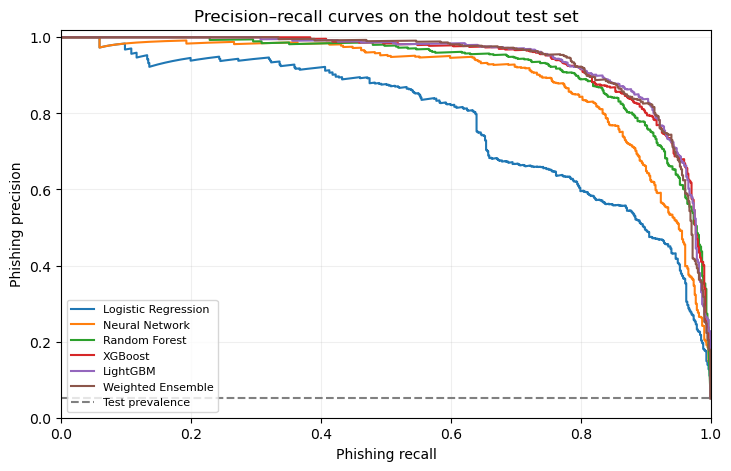

In [17]:
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
for name, probability in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    ax.plot(recall, precision, label=name)
ax.axhline(y_test.mean(), linestyle="--", color="0.5", label="Test prevalence")
ax.set(title="Precision–recall curves on the holdout test set",
       xlabel="Phishing recall", ylabel="Phishing precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "test_precision_recall.png", dpi=150)
plt.show()

## 8. Record the completed run

The receipt records the dataset checksum, split sizes, dependency versions and the optional analyses enabled for this run.

In [18]:
packages = ("numpy", "pandas", "scipy", "scikit-learn", "xgboost", "lightgbm", "matplotlib")
receipt = {
    "complete": True,
    "input_sha256": DATA_SHA256,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {name: version(name) for name in packages},
    "train_rows": len(y),
    "test_rows": len(y_test),
    "train_phishing": int(y.sum()),
    "test_phishing": int(y_test.sum()),
    "features": X.shape[1],
    "run_feature_ranking": RUN_FEATURE_RANKING,
    "ranking_baselines": ranking_baselines,
    "run_hyperparameter_search": RUN_HYPERPARAMETER_SEARCH,
    "elapsed_seconds": round(time.monotonic() - started, 1),
}
receipt_path.write_text(json.dumps(receipt, indent=2), encoding="utf-8")
print(f"Completed in {receipt['elapsed_seconds']:.1f}s. Results: {OUTPUT_DIR}/")

Completed in 60.8s. Results: outputs/
